In [7]:
#PROJET PYTHON & MACHINE LEARNING: 
#PROBLEMATIQUE:
#Analyse et prédiction de la qualité de l’air à Milan : étude des gaz polluants et de leur impact environnemental.
#Quel est le polluant ayant la concentration la plus élevée?
#Quel saison est la plus polluée?
#Quel facteur accentue le plus le polluant?
#Est ce que l'impact des polluants diminue de 2004 à 2005? 
#Quelle prediction du polluant le plus en vue?

In [8]:
# IMPORTATION DE...
import pandas as pd
import matplotlib.pyplot as plt 
import numpy as np
import seaborn as sns
from scipy import stats

In [9]:
#CHARGEMENT DE DATASET: 
df=pd.read_csv("AirQuality.csv", sep=";", decimal=",")

In [10]:
#APPERCU DE DONNEES: 
#On affiche les 10 premieres lignes des données. 
df.head(10)
#NB: Ayant remarqué la premiere de deux colonnes remplis de NaN, ne presentant aucune valeur, 
#De preference on procede à la suppression de ces deux colonnes(Unnamed15 et 16) pour aleger le jeu de données.

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,Unnamed: 15,Unnamed: 16
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,NaN,NaN
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,NaN,NaN
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,NaN,NaN
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,NaN,NaN
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,NaN,NaN
5,10/03/2004,23.00.00,1.2,1197.0,38.0,4.7,750.0,89.0,1337.0,96.0,1393.0,949.0,11.2,59.2,0.7848,NaN,NaN
6,11/03/2004,00.00.00,1.2,1185.0,31.0,3.6,690.0,62.0,1462.0,77.0,1333.0,733.0,11.3,56.8,0.7603,NaN,NaN
7,11/03/2004,01.00.00,1.0,1136.0,31.0,3.3,672.0,62.0,1453.0,76.0,1333.0,730.0,10.7,60.0,0.7702,NaN,NaN
8,11/03/2004,02.00.00,0.9,1094.0,24.0,2.3,609.0,45.0,1579.0,60.0,1276.0,620.0,10.7,59.7,0.7648,NaN,NaN
9,11/03/2004,03.00.00,0.6,1010.0,19.0,1.7,561.0,-200.0,1705.0,-200.0,1235.0,501.0,10.3,60.2,0.7517,NaN,NaN


In [11]:
df.shape

(9471, 17)

In [12]:
#NETTOYAGE DE LA DONNEE:
#Suppressions totale des colonnes vides:
df=df.dropna(axis=1, how='all')
print(df.columns)

Index(['Date', 'Time', 'CO(GT)', 'PT08.S1(CO)', 'NMHC(GT)', 'C6H6(GT)',
       'PT08.S2(NMHC)', 'NOx(GT)', 'PT08.S3(NOx)', 'NO2(GT)', 'PT08.S4(NO2)',
       'PT08.S5(O3)', 'T', 'RH', 'AH'],
      dtype='object')


In [13]:
#Aperçu aleatoire de données:
df.sample(3)

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
7813,30/01/2005,07.00.00,0.4,790.0,-200.0,0.4,431.0,53.0,1439.0,49.0,722.0,354.0,2.8,43.8,0.3308
415,28/03/2004,01.00.00,2.3,1274.0,101.0,8.3,912.0,111.0,939.0,97.0,1451.0,1188.0,10.3,58.1,0.7278
7598,21/01/2005,08.00.00,4.5,1501.0,-200.0,22.6,1367.0,766.0,465.0,174.0,1558.0,1856.0,7.2,62.2,0.6351


In [14]:
#Replacement du format Time, ajustement europeen: 
df["Time"]=df["Time"].str.replace(".",":", regex=False)
#Je remplace le "." par ":" pour favoriser la conversion en DateTime.

In [15]:
#Creation de la nouvelle colonne dateTime en remplacement et combinaison de la colonne Time et Date:
#La colonne Date: 
df["datetime"]=pd.to_datetime(df["Date"]+ " " +df["Time"], errors="coerce", format="%d/%m/%Y %H:%M:%S")
df.head()
#De là je cree une colonne unique et combinée permettant de d'avoir les données en heure et en date en une seule colonne en format europeen.

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,datetime
0,10/03/2004,18:00:00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,10/03/2004,19:00:00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,10/03/2004,20:00:00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,10/03/2004,21:00:00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,10/03/2004,22:00:00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


In [16]:
#Exploration des informtions de la donnée: 
df.info()
#Ci bas, on constate quon a un dataset de 9471 lignes et 15 colonnes de façon theorique puis pratiquement 
#9357 lignes et 15 colonnes car 2 colonnes(Unnameds) sont totalement vides et supprimées. 
#On peut tout de meme appercevoir des valeurs manquantes sur les données car le jeu est composé de 9357 lignes dont les valeurs manquantes cachées par des -200. 
#Ce dataset necessite forcement une conversion en Datetime au du format actuel en Object (entier)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9471 entries, 0 to 9470
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           9357 non-null   object        
 1   Time           9357 non-null   object        
 2   CO(GT)         9357 non-null   float64       
 3   PT08.S1(CO)    9357 non-null   float64       
 4   NMHC(GT)       9357 non-null   float64       
 5   C6H6(GT)       9357 non-null   float64       
 6   PT08.S2(NMHC)  9357 non-null   float64       
 7   NOx(GT)        9357 non-null   float64       
 8   PT08.S3(NOx)   9357 non-null   float64       
 9   NO2(GT)        9357 non-null   float64       
 10  PT08.S4(NO2)   9357 non-null   float64       
 11  PT08.S5(O3)    9357 non-null   float64       
 12  T              9357 non-null   float64       
 13  RH             9357 non-null   float64       
 14  AH             9357 non-null   float64       
 15  datetime       9357 n

In [17]:
#Suppresion des anciennes colonnes pour ne garder que la nouvelle crée et combinée: 
df.drop(columns=["Date", "Time"], inplace=True)

In [18]:
# Statistiques sur les colonnes numerques: 
print("\n statistiques descriptives:")
df.describe(include="number").round(2)
#On peut bien appercevoir des valeurs manquantes codées (-200) puis la presence potentielle des outliers(valeurs aberantes) au vue de l'ecart entre le premier quantile et la valeur minimale. 
#Tout comme entre le 3e quantile et la valeur maximale.
#On a des valeurs non numerique (NAN) ainsi aue des valeurs manquantes cachées(-200) repetitive.


 statistiques descriptives:


,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00,9357.00
mean,-34.21,1048.99,-159.09,1.87,894.60,168.62,794.99,58.15,1391.48,975.07,9.78,39.49,-6.84
std,77.66,329.83,139.79,41.38,342.33,257.43,321.99,126.94,467.21,456.94,43.20,51.22,38.98
min,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00,-200.00
25%,0.60,921.00,-200.00,4.00,711.00,50.00,637.00,53.00,1185.00,700.00,10.90,34.10,0.69
50%,1.50,1053.00,-200.00,7.90,895.00,141.00,794.00,96.00,1446.00,942.00,17.20,48.60,0.98
75%,2.60,1221.00,-200.00,13.60,1105.00,284.00,960.00,133.00,1662.00,1255.00,24.10,61.90,1.30
max,11.90,2040.00,1189.00,63.70,2214.00,1479.00,2683.00,340.00,2775.00,2523.00,44.60,88.70,2.23


In [19]:
#Verification de types de colonnes: 
df.dtypes

CO(GT)                  float64
PT08.S1(CO)             float64
NMHC(GT)                float64
C6H6(GT)                float64
PT08.S2(NMHC)           float64
NOx(GT)                 float64
PT08.S3(NOx)            float64
NO2(GT)                 float64
PT08.S4(NO2)            float64
PT08.S5(O3)             float64
T                       float64
RH                      float64
AH                      float64
datetime         datetime64[ns]
dtype: object

In [20]:
#Verification de la taille de dataset:
df.shape

(9471, 14)

In [21]:
#Affichage de la dataset apres conversion et retrait de colonnes puis ajout de colonne combinée datetime.
df.head()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,datetime
0,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


In [22]:
#Verification de la presence des doublons:
#Au vue de la taille de donnée, on constate des valeurs repetitives devons etre supprimées ou remplacer.
print("\n Afficher le nombre de doublons presents:", df.duplicated().sum())
#N.B: On a 113 doublons


 Afficher le nombre de doublons presents: 113


In [23]:
#Suppression du nombre de doublons: 
Df=df.drop_duplicates()
#Verification:
print("\n Afficher le nombre de doublons restants:", Df.duplicated().sum())
#Apres nettoyage de doublons, on se retrouve avec 0 doublons.


 Afficher le nombre de doublons restants: 0


In [24]:
#Verification de la nouvelle taille du jeu de donnée:
len(Df)
#Cette correspond la taille de notre jeu de donnée apres suppression de doublons.

9358

In [25]:
#Detection de Veleurs manquantes: 
Df.isna()
# On peut constater enormement de valeurs manquantes dans la plupat de colonnes, cela fait alors objet de traitement de valeurs manquantes:

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,datetime
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9353,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9354,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9355,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9356,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [26]:
#Verification des colonnes concernées: 
Df.isna().any()
#Il est bien claire que toutes les colonnes ont au moins une valeur manquante.

CO(GT)           True
PT08.S1(CO)      True
NMHC(GT)         True
C6H6(GT)         True
PT08.S2(NMHC)    True
NOx(GT)          True
PT08.S3(NOx)     True
NO2(GT)          True
PT08.S4(NO2)     True
PT08.S5(O3)      True
T                True
RH               True
AH               True
datetime         True
dtype: bool

In [27]:
#Affichage du nombre de valeurs de manquantes par colonnes: 
Df.isnull().sum()

CO(GT)           1
PT08.S1(CO)      1
NMHC(GT)         1
C6H6(GT)         1
PT08.S2(NMHC)    1
NOx(GT)          1
PT08.S3(NOx)     1
NO2(GT)          1
PT08.S4(NO2)     1
PT08.S5(O3)      1
T                1
RH               1
AH               1
datetime         1
dtype: int64

In [28]:
#Nouvel appreçu de 5 premieres lignes de données:
Df.head()

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH,datetime
0,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578,2004-03-10 18:00:00
1,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255,2004-03-10 19:00:00
2,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502,2004-03-10 20:00:00
3,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867,2004-03-10 21:00:00
4,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888,2004-03-10 22:00:00


In [29]:
#TRAITEMENT DES VALEURS MANQUANTES:
#Remplacements des valeurs manquantes sur les données de capteurs et polluants par la mediane:
#Pour eviter de totalement supprimer les valeur manquantes au risque de bouleverser les données, on opte par le remplecement de celles ci par la mediane, la moyenne.
Df=df.copy()
Df=Df.drop_duplicates()
Df.replace(-200, np.nan, inplace=True)
median_cols=["CO(GT)","PT08.S1(CO)","NMHC(GT)","C6H6(GT)","PT08.S2(NMHC)","NOx(GT)","PT08.S3(NOx)","NO2(GT)","PT08.S4(NO2)","PT08.S5(O3)"]
for col in median_cols:
    Df[col]=Df[col].fillna(Df[col].median())


In [30]:
print("Lignes :", Df.shape[0])
print("Doublons :", Df.duplicated().sum())

Lignes : 9358
Doublons : 0


In [31]:
#Remplacement des valeurs manquantes sur les données environnementales(Humidité) par la moyenne:
moy_cols = ["T", "RH", "AH"]
for col in moy_cols:
    Df[col]=Df[col].fillna(Df[col].mean())

In [32]:
#Remplacement des valeurs manquantes sur les données horaires (datetime) par le mode(Les jours et horaires les plus reccurrents pour les analyses):
DateTime_Mode=Df["datetime"].mode()
Df["datetime"]=Df["datetime"].fillna(DateTime_Mode[0])

In [33]:
#Verification de la presence des valeurs manquantes: 
print("\n valeurs manquantes restantes apres nettoyage est:", Df.isna().sum())
#On peut constater que l'on a pplus de valeurs manquantes car elles ont toutes ete remplacées/traitées.


 valeurs manquantes restantes apres nettoyage est: CO(GT)           0
PT08.S1(CO)      0
NMHC(GT)         0
C6H6(GT)         0
PT08.S2(NMHC)    0
NOx(GT)          0
PT08.S3(NOx)     0
NO2(GT)          0
PT08.S4(NO2)     0
PT08.S5(O3)      0
T                0
RH               0
AH               0
datetime         0
dtype: int64


In [34]:
#DETECTION DE VALEURS ABERRANTES: Outiers.
Df.describe(include="number").round(2)

,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
count,9358.00,9358.00,9358.00,9358.00,9358.00,9358.00,9358.00,9358.00,9358.00,9358.00,9358.00,9358.00,9358.00
mean,2.09,1098.39,156.72,10.01,937.97,235.17,834.34,112.37,1456.53,1020.56,18.32,49.23,1.03
std,1.32,212.90,67.05,7.31,261.61,195.08,251.80,43.95,339.35,390.76,8.66,16.97,0.40
min,0.10,647.00,7.00,0.10,383.00,2.00,322.00,2.00,551.00,221.00,-1.90,9.20,0.18
25%,1.20,941.00,150.00,4.60,743.00,112.00,666.00,86.00,1242.00,742.00,12.00,36.60,0.75
50%,1.80,1063.00,150.00,8.20,909.00,180.00,806.00,109.00,1463.00,963.00,18.30,49.23,1.02
75%,2.60,1221.00,150.00,13.60,1105.00,284.00,960.00,133.00,1662.00,1255.00,24.10,61.90,1.30
max,11.90,2040.00,1189.00,63.70,2214.00,1479.00,2683.00,340.00,2775.00,2523.00,44.60,88.70,2.23


In [35]:
##Compte tenu de cette description statistique, il est à constrater qu'on a bel et bien 9358 lignes de données pour 14 colonnes. 
#Bien que le dataset est propre et bien nettoyé, mais on peut encore appercevoir des outliers/valeurs aberrantes, justifiées par l'ecart entre le troisieme quartile et le maximum entre les polluants, 
# pour le Monoxyde de carbone avec une moyenne superieur à la mediane, une forte polution possible, soit la presence des outliers.
#celle ne vont pas etre supprimées, car elles peuvent representées des pics de pollutions ou autres phenomenes environnementales necessaire pour la suite du rapport.

In [36]:
#DETECTION ET TRAITEMENT DES VALEURS ABERRANTES: OUTLIERS.
# Methode IQR: 
# Colonnes numériques du dataset à analyser pour les outliers:
colonnes=["CO(GT)","NMHC(GT)","C6H6(GT)","NOx(GT)","NO2(GT)","PT08.S1(CO)","PT08.S2(NMHC)","PT08.S3(NOx)","PT08.S4(NO2)","PT08.S5(O3)","T","RH","AH"]
#Calcul de Q1, Q3 et IQR:

Q1=Df[colonnes].quantile(0.25)
Q3=Df[colonnes].quantile(0.75)
    
IQR=Q3 - Q1

#DETECTION DES OUTLIERS:
outliers_X = ((Df[colonnes] < (Q1 - 1.5 * IQR))|(Df[colonnes] > (Q3 + 1.5 * IQR)))

#Lignes contenant au moins un outlier:
outliers=Df[outliers_X.any(axis=1)]
#Affichage des outliers detectés:
print("\n Nombre de lignes avec valeurs aberrantes:", len(outliers))
outliers.head()
print(outliers)
#On peut constater, quon a au moins 2183 lignes ayant des valeurs aberrantes, soit des outliers.
#Un pourcentage enorme soit 23,98% de la donnée.


 Nombre de lignes avec valeurs aberrantes: 2183
      CO(GT)  PT08.S1(CO)  NMHC(GT)  C6H6(GT)  PT08.S2(NMHC)  NOx(GT)  \
1        2.0       1292.0     112.0       9.4          955.0    103.0   
2        2.2       1402.0      88.0       9.0          939.0    131.0   
3        2.2       1376.0      80.0       9.2          948.0    172.0   
4        1.6       1272.0      51.0       6.5          836.0    131.0   
5        1.2       1197.0      38.0       4.7          750.0     89.0   
...      ...          ...       ...       ...            ...      ...   
9207     4.3       1409.0     150.0      18.8         1262.0    606.0   
9253     4.0       1531.0     150.0      23.6         1394.0    673.0   
9254     4.1       1184.0     150.0      10.9         1012.0    547.0   
9349     4.0       1384.0     150.0      17.4         1221.0    594.0   
9350     5.0       1446.0     150.0      22.4         1362.0    586.0   

      PT08.S3(NOx)  NO2(GT)  PT08.S4(NO2)  PT08.S5(O3)     T    RH      AH

In [37]:
#Nombre d'outiers par colonnes: 
nb_outliers=outliers_X.sum()
print("Nombre d'outliers par variables:")
print(nb_outliers)
#De ce resultat on peut remarquer que la concentration polluant NMHC(Hydrocarbures non methaniaue) est à 909, soit pres de 90% de sa presence est remplie de 909 outliers. 
#Inutile de le garder pour le reste du reste du travail vu le nombre de valeur manquante.

Nombre d'outliers par variables:
CO(GT)           454
NMHC(GT)         909
C6H6(GT)         286
NOx(GT)          778
NO2(GT)          380
PT08.S1(CO)      145
PT08.S2(NMHC)     91
PT08.S3(NOx)     278
PT08.S4(NO2)     131
PT08.S5(O3)      131
T                 10
RH                 0
AH                 7
dtype: int64


In [38]:
nb_outliers = outliers_X.any(axis=1).sum()
pourcentage= nb_outliers/ len(Df)*100
print(nb_outliers)
print(f"{pourcentage:.2f}%")
#La méthode IQR a permis d'identifier 2183 observations contenant au moins une valeur aberrante, soit 23,32 % du jeu de données. Ce pourcentage étant relativement élevé, la suppression de ces observations aurait entraîné une perte importante d'information et une altération de la représentativité des phénomènes de pollution étudiés. Par conséquent, les valeurs aberrantes ont été conservées.

2183
23.33%


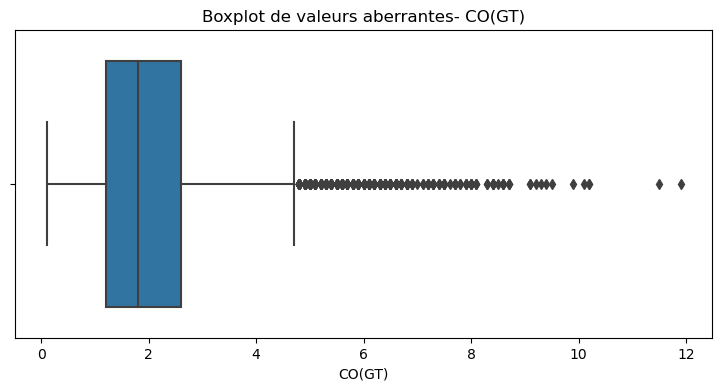

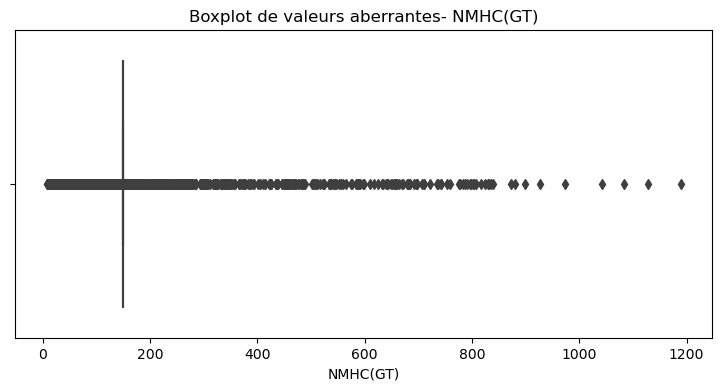

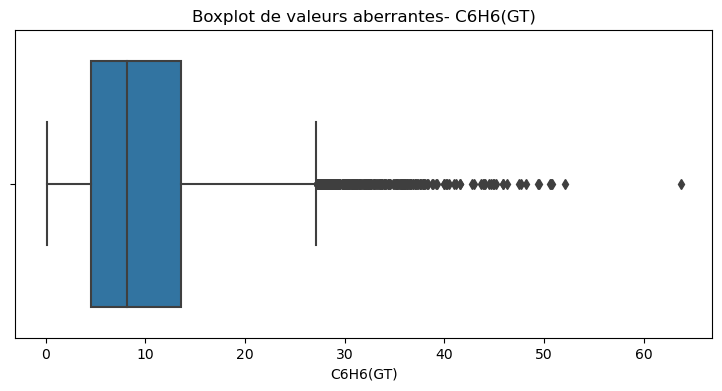

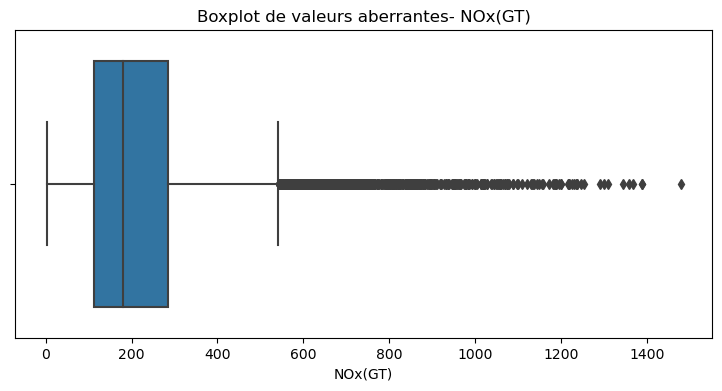

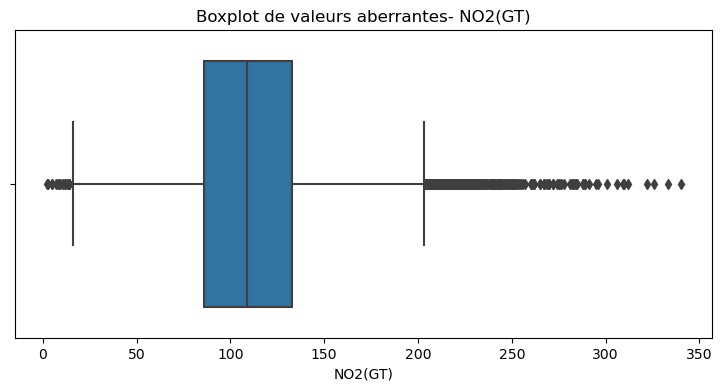

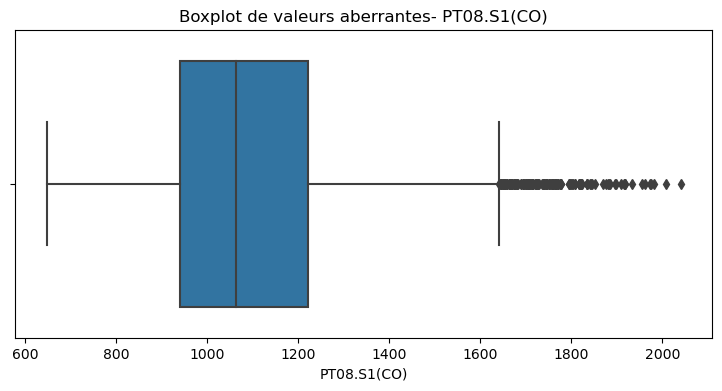

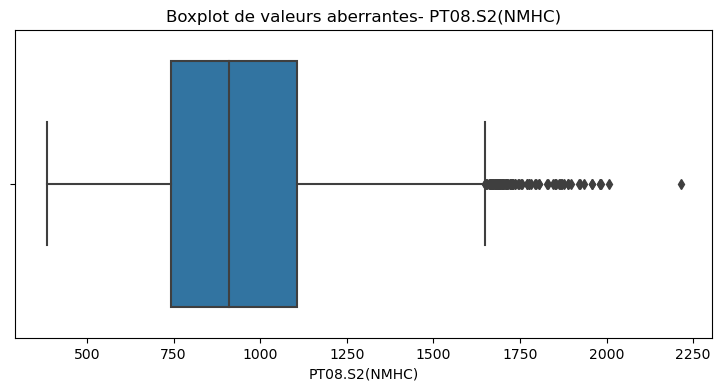

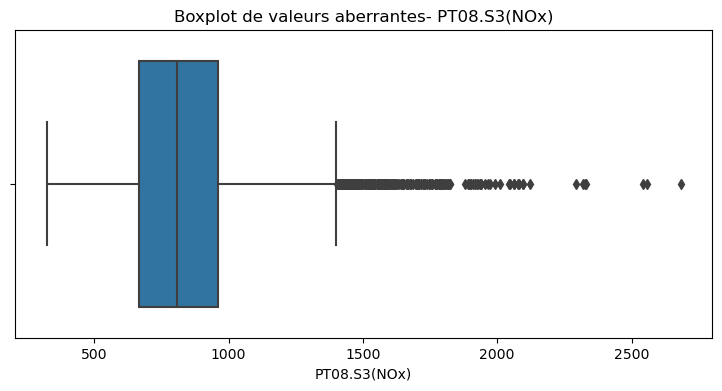

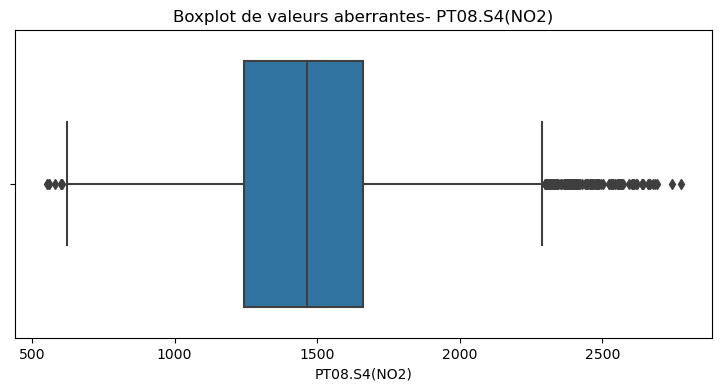

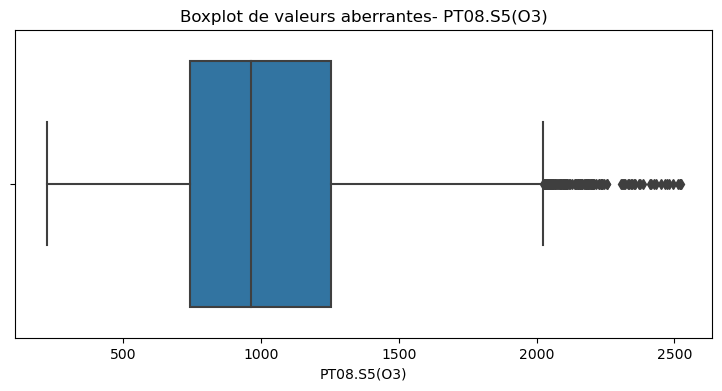

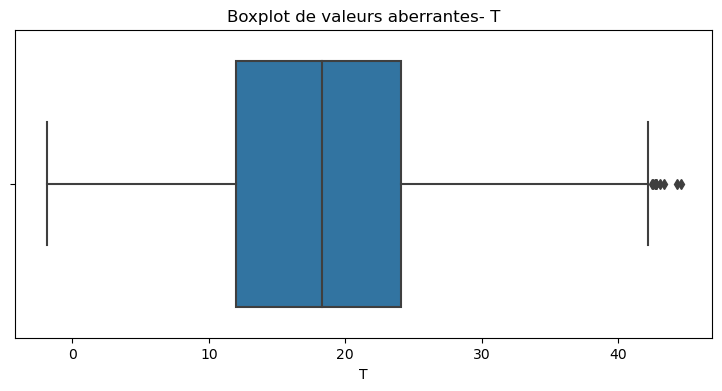

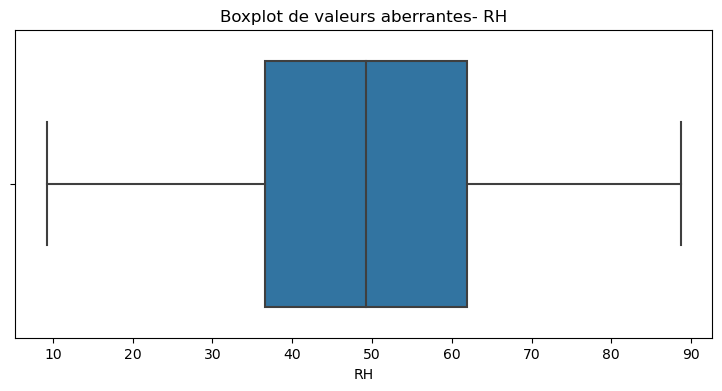

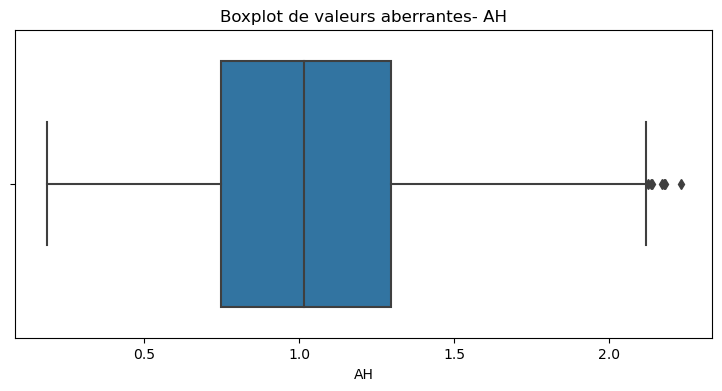

In [39]:
#Visualisation des outliers avec des boxplots:
for col in colonnes:

    plt.figure(figsize=(9,4))
    sns.boxplot(x=Df[col])
    plt.title(f"Boxplot de valeurs aberrantes- {col}")
    plt.show()
    
    #Vu que ces valeurs aberrantes re^presentent des observations impotantes pour notre anasye, le meiux seraient de ne pas les supprimer.
    

In [40]:
#Concentration minale de l'Humidité absolue:
Df["AH"].min()

0.1847

In [41]:
#Conservation des Outliers tout en creant une colonne binaire:  
Df["is_outlier"]=Df.index.isin(outliers.index).astype(int)
#Comme mentionner ci dessus, afin d'eviter la suppression des valeurs extremes liées au condition environnemental ou meteorologique, je cree une valeur binaire is_outlier permettant de conserver les données aberrantes. 

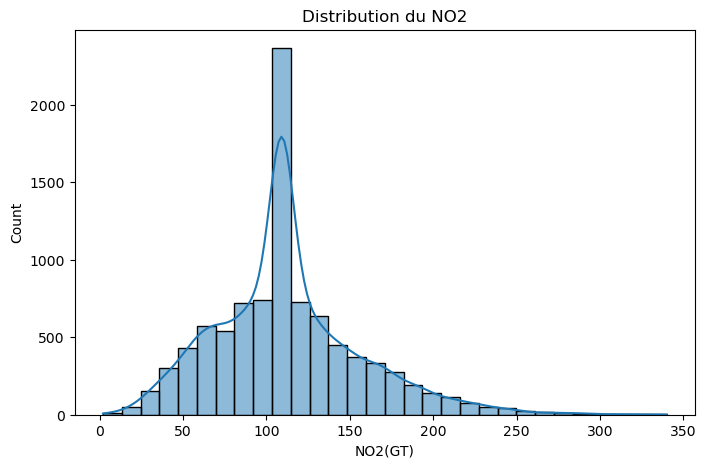

In [42]:
#ANALYSE EXPLORATOIRE DE DONNEES:
#Etude de distribution de differents polluants:
plt.figure(figsize=(8,5))
sns.histplot(Df["NO2(GT)"], bins=30, kde=True)
plt.title("Distribution du NO2")
plt.show()
#La forte asumetrie du NO2 indique la presence de pics important de pllution liés au trafic routier ou à de certaines conditions meteorologiques.

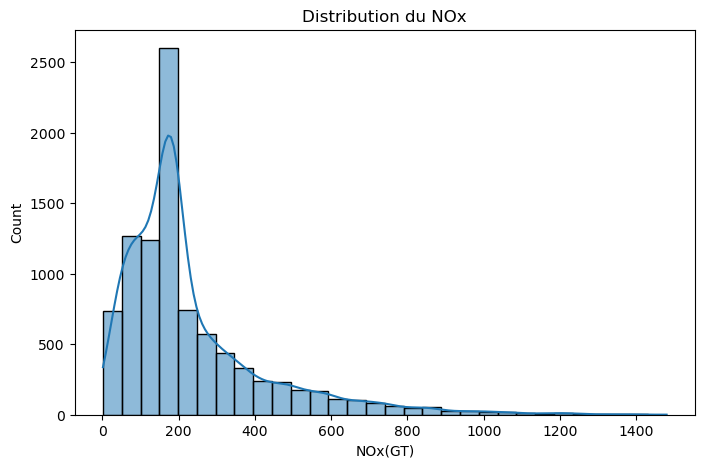

In [43]:
plt.figure(figsize=(8,5))
sns.histplot(Df["NOx(GT)"], bins=30, kde=True)
plt.title("Distribution du NOx")
plt.show()

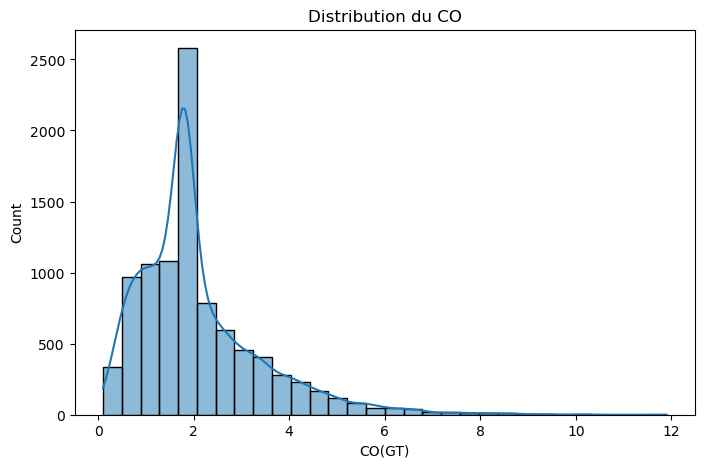

In [44]:
plt.figure(figsize=(8,5))
sns.histplot(Df["CO(GT)"], bins=30, kde=True)
plt.title("Distribution du CO")
plt.show()

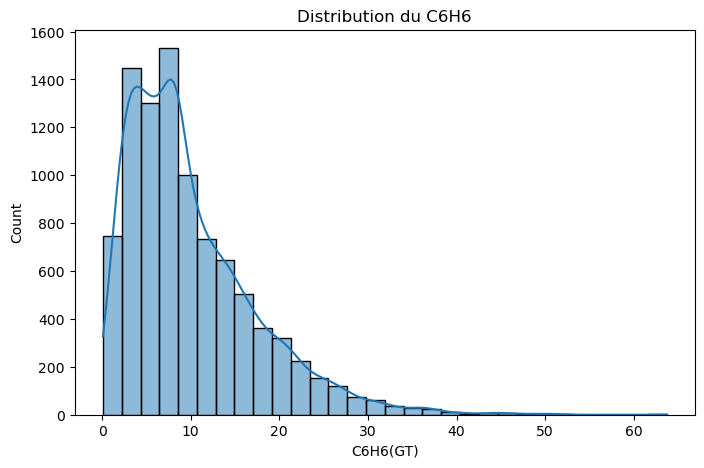

In [45]:
plt.figure(figsize=(8,5))
sns.histplot(Df["C6H6(GT)"], bins=30, kde=True)
plt.title("Distribution du C6H6")
plt.show()

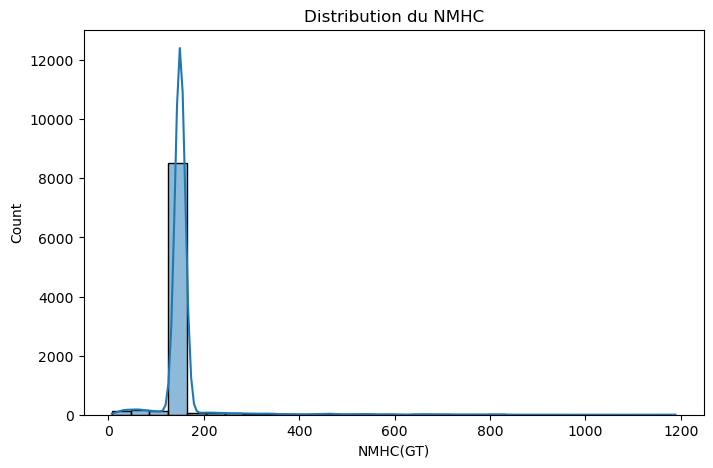

In [46]:
plt.figure(figsize=(8,5))
sns.histplot(Df["NMHC(GT)"], bins=30, kde=True)
plt.title("Distribution du NMHC")
plt.show()

In [47]:
#Obesrvation de la concentration etrange de NMHC: 
#On peut remaquer que dans cette distribution la valeur 150 reapparait 8449 fois dans la donnée, ce qui ne fournit pas assez d'information d'ou l'ideal de la supprimer.
Df["NMHC(GT)"].value_counts().head()

NMHC(GT)
150.0    8449
66.0       14
40.0        9
29.0        9
93.0        8
Name: count, dtype: int64

In [48]:
#Suppression de la colonne NMHC:
Df=Df.drop(columns=["NMHC(GT)"])
#Vue le taux de valeurs manquantes dans la colonne NMHC faisant objet des resultats irrelles du terrain bien que 
#remplacer par la mediane, ces valeurs ne font pas grande utilité pour mon  etude, d'ou la suppression.
#La variable NMHC(GT) a été retirée de l'analyse. Plus de 90 % de ses observations étaient manquantes dans le jeu de données d'origine. Malgré une possible imputation, la quantité d'informations réelles disponibles était insuffisante pour garantir une interprétation statistique fiable. Son exclusion permet d'améliorer la robustesse des analyses et des modèles développés.

In [49]:
#Verification des informations du dataset:
Df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9358 entries, 0 to 9357
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   CO(GT)         9358 non-null   float64       
 1   PT08.S1(CO)    9358 non-null   float64       
 2   C6H6(GT)       9358 non-null   float64       
 3   PT08.S2(NMHC)  9358 non-null   float64       
 4   NOx(GT)        9358 non-null   float64       
 5   PT08.S3(NOx)   9358 non-null   float64       
 6   NO2(GT)        9358 non-null   float64       
 7   PT08.S4(NO2)   9358 non-null   float64       
 8   PT08.S5(O3)    9358 non-null   float64       
 9   T              9358 non-null   float64       
 10  RH             9358 non-null   float64       
 11  AH             9358 non-null   float64       
 12  datetime       9358 non-null   datetime64[ns]
 13  is_outlier     9358 non-null   int32         
dtypes: datetime64[ns](1), float64(12), int32(1)
memory usage: 1.0 MB


In [50]:
#Ideale de passer les tests de: voir court
#Skewness + QQ-Plot + tests de corrélation:
for col in ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)", "T", "RH", "AH"]:
    print(col, ":", Df[col].skew().round(2))
    #Commentaire à ajouter

CO(GT) : 1.63
C6H6(GT) : 1.41
NOx(GT) : 2.01
NO2(GT) : 0.73
T : 0.32
RH : -0.04
AH : 0.26


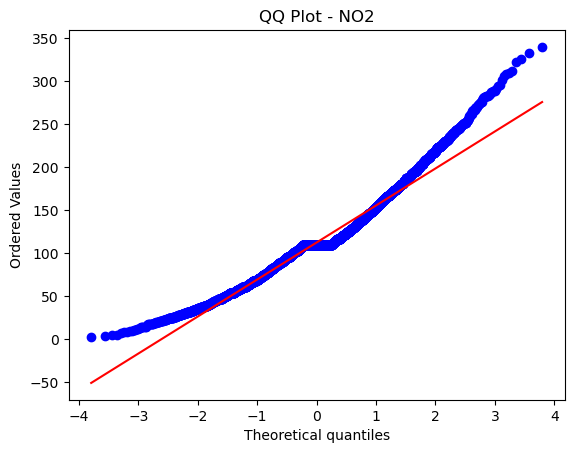

In [51]:
#QQ-Plot
stats.probplot(Df["NO2(GT)"], dist="norm", plot=plt)
plt.title("QQ Plot - NO2")
plt.show()
#Commentaire à ajouter

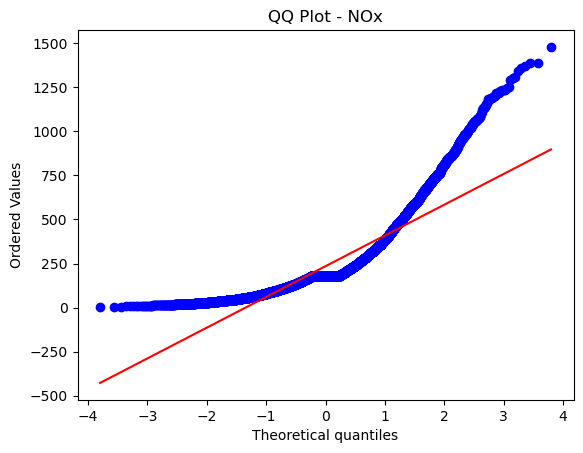

In [52]:
#QQ-Plot
stats.probplot(Df["NOx(GT)"], dist="norm", plot=plt)
plt.title("QQ Plot - NOx")
plt.show()
#Cette dsitribution confirme la presence de valeurs extremes, fort pics de pollution car les valeurs s'ecartent enormement de la ligne principale 

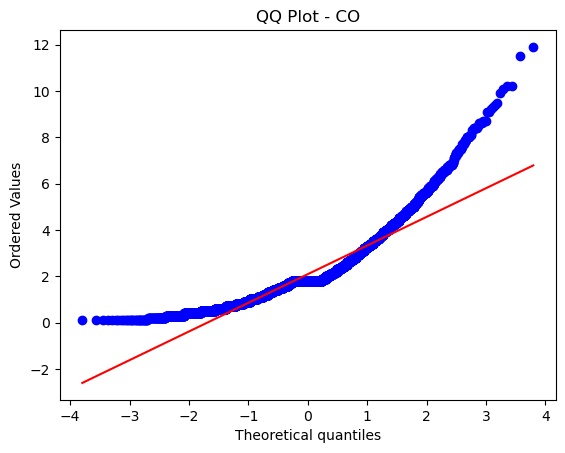

In [53]:
#QQ-Plot
stats.probplot(Df["CO(GT)"], dist="norm", plot=plt)
plt.title("QQ Plot - CO")
plt.show()
#La distribution modérément asymétrique à droite. La normalité n'est pas respectée en raison de quelques concentrations élevées observées lors d'épisodes de pollution.

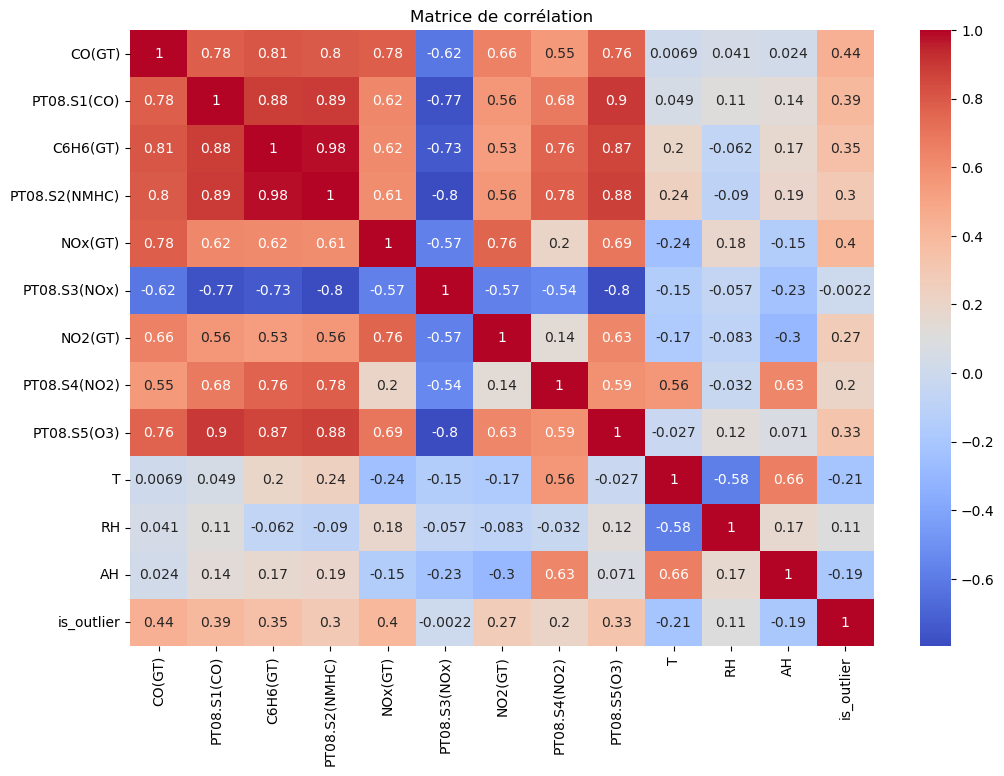

In [54]:
#Matrice de correlation:

plt.figure(figsize=(12,8))
sns.heatmap(Df.corr(numeric_only=True),annot=True,cmap="coolwarm")
plt.title("Matrice de corrélation")
plt.show()

In [55]:
#Creation de variables temporelles:
Df["Year"]=Df["datetime"].dt.year
Df["Month"]=Df["datetime"].dt.month
Df["Day"]=Df["datetime"].dt.day
Df["Hour"]=Df["datetime"].dt.hour

#Creation de la variable saison (Season) pour enfin voir l'impact des polluants par diferentes saison:

Df["Season"] = Df["Month"].map({
    12:"Winter", 1:"Winter", 2:"Winter",
    3:"Spring", 4:"Spring", 5:"Spring",
    6:"Summer", 7:"Summer", 8:"Summer",
    9:"Autumn", 10:"Autumn", 11:"Autumn"})

print(Df["Season"].value_counts())
#On a le ombre d'observation par saison:

Season
Spring    2806
Summer    2208
Autumn    2184
Winter    2160
Name: count, dtype: int64


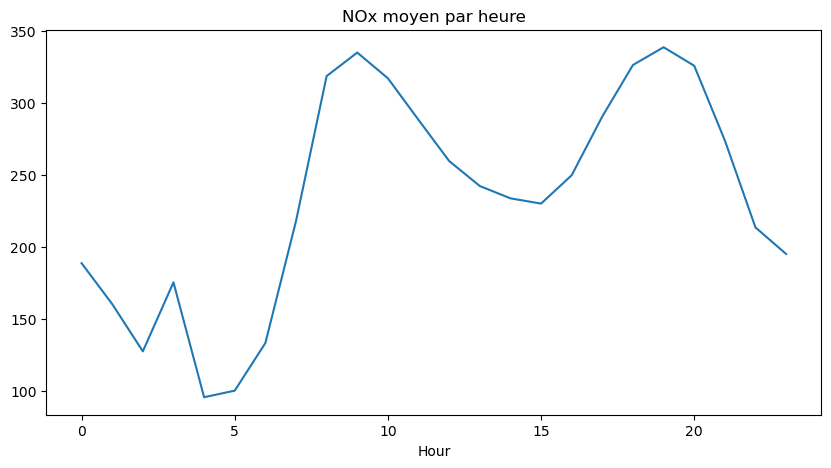

In [56]:
#Etude d'impact de chaque polluant par mois, heure,jours et annnée:
Df.groupby("Hour")["NOx(GT)"].mean().plot(figsize=(10,5))
plt.title("NOx moyen par heure")
plt.show()

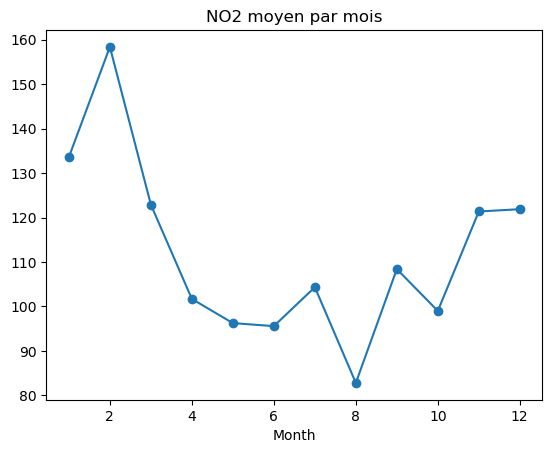

In [57]:

Df.groupby("Month")["NO2(GT)"].mean().plot(marker="o")
plt.title("NO2 moyen par mois")
plt.show()

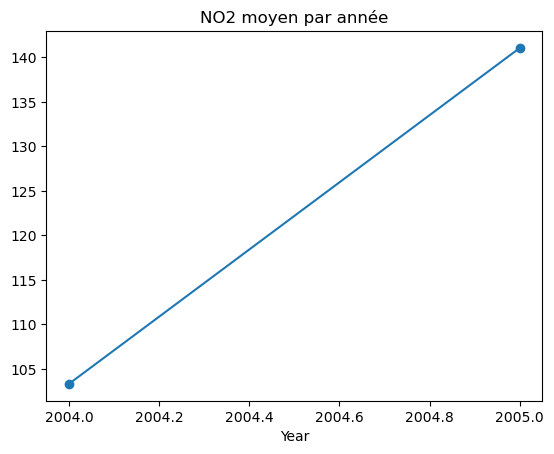

In [58]:

Df.groupby("Year")["NO2(GT)"].mean().plot(marker="o")
plt.title("NO2 moyen par année")
plt.show()

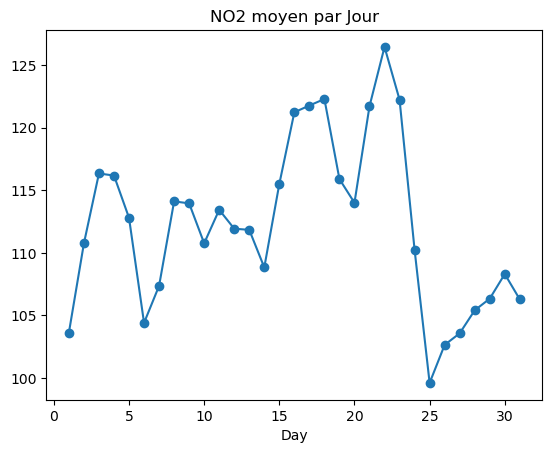

In [59]:
Df.groupby("Day")["NO2(GT)"].mean().plot(marker="o")
plt.title("NO2 moyen par Jour")
plt.show()

In [60]:
# Polluants à étudier
polluants = ["CO(GT)", "C6H6(GT)", "NOx(GT)", "NO2(GT)"]

# Moyenne par saison
pollution_saison = Df.groupby("Season")[polluants].mean().round(2)

print("Moyenne des polluants par saison :")
print(pollution_saison)

#On peut appercevoir que l'hiver la saison la plus polluée. Il fait plus froid, baise de temperatire, chaufage plus present...une inversion thermique totale.

Moyenne des polluants par saison :
        CO(GT)  C6H6(GT)  NOx(GT)  NO2(GT)
Season                                    
Autumn    2.33     12.51   302.01   109.48
Spring    2.05      9.60   188.14   109.74
Summer    1.71      9.37   122.13    94.22
Winter    2.28      8.67   344.24   137.28


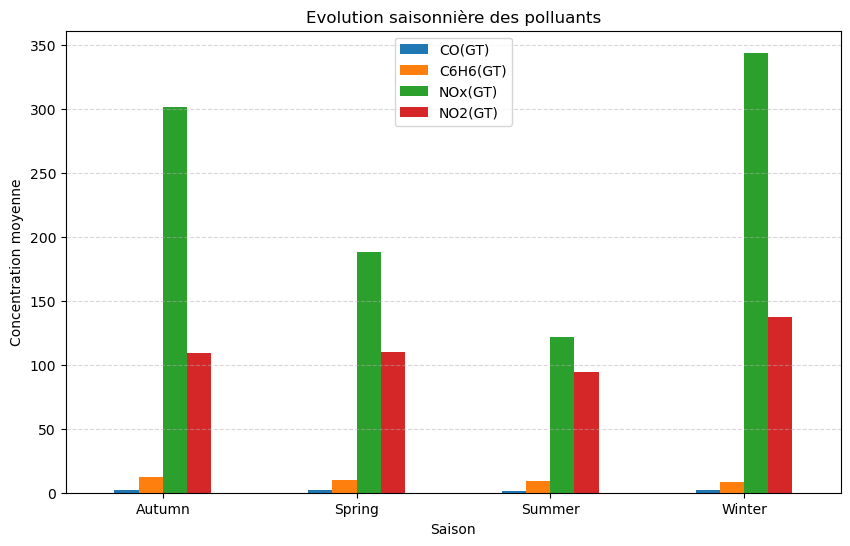

In [61]:
#Evolution saisonniere des polluants:
pollution_saison.plot(kind="bar",figsize=(10,6))
plt.title("Evolution saisonnière des polluants")
plt.xlabel("Saison")
plt.ylabel("Concentration moyenne")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.show()
#On peut appercevoir un grand pic en hiver ed NOx et le NO2 bien que plus bas par rapport au NOx mais plus elevée que d'habitude.

In [62]:
#Comparatif des pics de polluants par saison:
for polluant in polluants:
    saison_max = pollution_saison[polluant].idxmax()
    valeur_max = pollution_saison[polluant].max()

    print(f"{polluant} : maximum en {saison_max} ({valeur_max:.2f})")

CO(GT) : maximum en Autumn (2.33)
C6H6(GT) : maximum en Autumn (12.51)
NOx(GT) : maximum en Winter (344.24)
NO2(GT) : maximum en Winter (137.28)


In [63]:
#COMMENTAIRE SUR l'ANALYSE SAISONNIERE:
#D'après les résultats obtenus, l'hiver apparaît comme la saison la plus polluée. En effet, les concentrations moyennes de NOx(GT) (344,24) et NO2(GT) (137,28), deux indicateurs majeurs de la pollution atmosphérique urbaine, y atteignent leurs niveaux les plus élevés. Cette situation s'explique principalement par l'augmentation des émissions liées au chauffage domestique et par les conditions météorologiques hivernales, notamment les inversions thermiques, qui limitent la dispersion des polluants. Bien que le CO(GT) et le benzène (C6H6(GT)) présentent leurs maxima en automne, les concentrations particulièrement élevées des oxydes d'azote en hiver indiquent une dégradation plus importante de la qualité de l'air durant cette saison. On peut donc conclure que l'hiver constitue la période la plus critique en matière de pollution atmosphérique à Milan.

In [64]:
#Telechargement de la version CSV:
Df.to_csv("AirQuality_propre.csv", index=False)

In [65]:
#Telechargement de la version Excel:
Df.to_excel("AirQuality_propre.xlsx", index=False)